In [4]:
import pandas as pd

# 1. Carregar a base
df = pd.read_csv("87-Site_DKA-M9_A+C-Phases.csv")

# 2. Converter a coluna de data para datetime
# Substitua "Date/Time" pelo nome da coluna de data da sua base
coluna_data = "timestamp"

df[coluna_data] = pd.to_datetime(
    df[coluna_data],
    errors="coerce"
)

# 3. Ordenar cronologicamente
df = df.dropna(subset=[coluna_data])
df = df.sort_values(coluna_data)

# 4. Selecionar todas as variáveis numéricas
colunas_numericas = df.select_dtypes(
    include="number"
).columns

# 5. Agrupar por dia e calcular a média
df_diario = (
    df.set_index(coluna_data)
      .resample("D")[colunas_numericas]
      .mean()
      .dropna(how="all")
      .reset_index()
)

# 6. Exibir resultado
print("Base original:", df.shape)
print("Base diária:", df_diario.shape)

display(df_diario.head())

# 7. Salvar em CSV
df_diario.to_csv(
    "base_diaria_australia.csv",
    index=False
)


Base original: (1256431, 13)
Base diária: (4378, 13)


,timestamp,Active_Energy_Delivered_Received,Current_Phase_Average,Active_Power,Wind_Speed,Weather_Temperature_Celsius,Weather_Relative_Humidity,Global_Horizontal_Radiation,Diffuse_Horizontal_Radiation,Wind_Direction,Weather_Daily_Rainfall,Radiation_Global_Tilted,Radiation_Diffuse_Tilted
0,2013-07-25,229537.449438,5.809569,1.154285,1.560917,9.814493,46.496349,30.779956,7.295517,45.372042,0.0,52.669826,8.334659
1,2013-07-26,229600.989583,24.390068,5.757675,1.655984,10.662288,48.019982,220.014002,19.209335,150.557047,0.0,298.788367,22.399470
2,2013-07-27,229751.461806,28.280212,6.672181,2.067072,15.328865,36.919263,216.823209,20.195084,103.101980,0.0,3.814177,1.971192
3,2013-07-28,229909.697917,27.627000,6.530677,1.469911,15.945440,34.397319,216.997481,24.312928,137.380681,0.0,NaN,NaN
4,2013-07-29,230069.239583,28.596213,6.766403,2.070920,13.212559,47.947853,215.792656,20.831585,117.692408,0.0,NaN,NaN


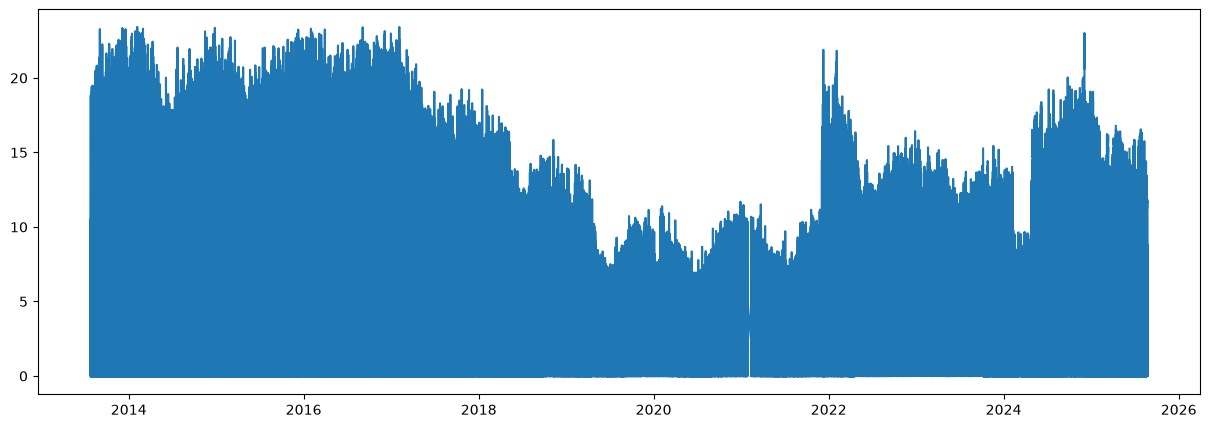

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,5))
plt.plot(df['timestamp'], df['Active_Power'])
plt.show()